In [1]:
!apt-get install -y tesseract-ocr
!pip install -q pytesseract opencv-python-headless pillow

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [2]:
import cv2, pytesseract
print("OpenCV:", cv2.__version__)
print("Tesseract:", pytesseract.get_tesseract_version())

OpenCV: 4.14.0
Tesseract: 5.3.4


In [3]:
from google.colab import files

uploaded = files.upload()
img_path = list(uploaded.keys())[0]
print("Uploaded:", img_path)

Saving download.png to download.png
Uploaded: download.png


In [4]:
import cv2
import matplotlib.pyplot as plt

# 1. Load the image
img = cv2.imread(img_path)

# 2. Grayscale — collapse 3 colour channels into 1 intensity channel.
#    Colour carries no information for reading text, so we drop it.
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. Gaussian Blur — smooths out tiny specks and noise,
#    so the next step doesn't mistake a speck for a letter.
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# 4. Adaptive Threshold (Otsu) — forces every pixel to pure black or white.
#    Otsu finds the best cutoff automatically. This is the PDF's
#    "forcing the binary decision" step.
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

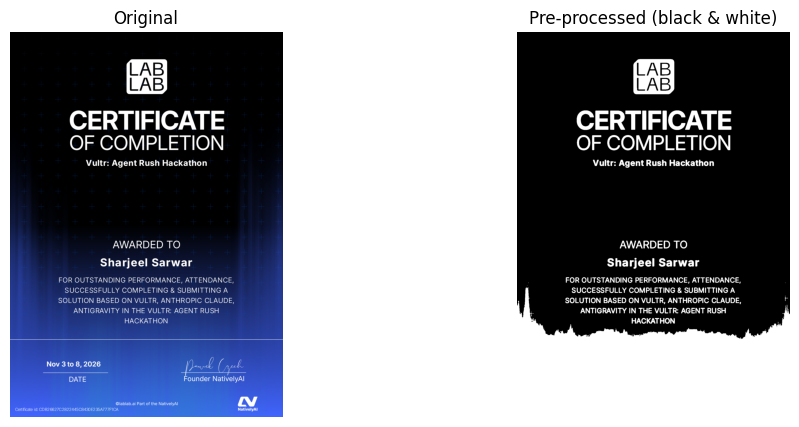

In [5]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Pre-processed (black & white)")
plt.axis("off")
plt.show()

In [6]:
import pytesseract

# Flip it: dark text on light background, the way Tesseract expects
inverted = cv2.bitwise_not(thresh)

# Read the text. PSM 6 = one uniform block of text (a certificate is one block)
text = pytesseract.image_to_string(inverted, config="--psm 6")
print(text)

Vultr: Agent Rush Hackathon
AWARDED TO
Sharjeel Sarwar
. FOR OUTSTANDING PERFORMANCE, ATTENDANCE,
SUCCESSFULLY COMPLETING & SUBMITTING A

SOLUTION BASED ON VULTR, ANTHROPIC CLAUDE, F
ANTIGRAVITY IN THE VULTR: AGENT RUSH

HACKATHON i



In [7]:
data = pytesseract.image_to_data(inverted, config="--psm 6", output_type=pytesseract.Output.DATAFRAME)
words = data.dropna(subset=["text"])
words = words[words.conf >= 0]

mean_conf = words["conf"].mean()
print("Mean confidence:", round(mean_conf, 1), "%")
print("Words above 80%:", int((words["conf"] >= 80).sum()), "of", len(words))

# The PDF's rule: 80% is the absolute minimum
if mean_conf >= 80:
    print("PASS — above the 80% minimum")
else:
    print("FAIL — below 80%, need a cleaner image or different PSM")

Mean confidence: 89.1 %
Words above 80%: 30 of 33
PASS — above the 80% minimum


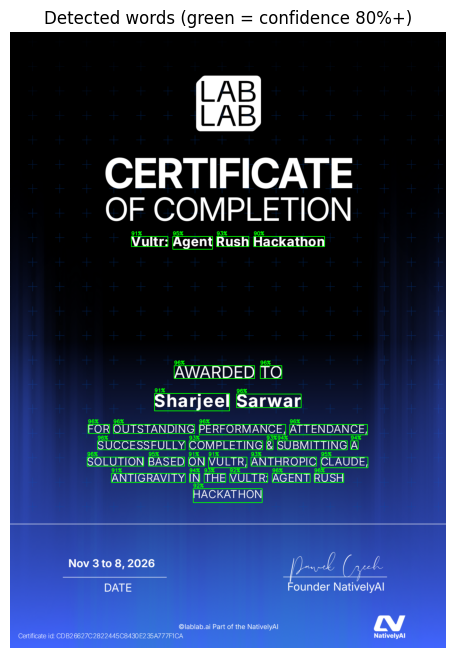

In [8]:
# Draw a box around every word Tesseract found (only the confident ones)
boxed = img.copy()
for _, row in words.iterrows():
    x, y, w, h = int(row["left"]), int(row["top"]), int(row["width"]), int(row["height"])
    conf = row["conf"]
    if conf >= 80:
        cv2.rectangle(boxed, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(boxed, f"{int(conf)}%", (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB))
plt.title("Detected words (green = confidence 80%+)")
plt.axis("off")
plt.show()